In [43]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

nltk.download('stopwords')

from nltk.corpus import stopwords

print("All libraries imported successfully!")

All libraries imported successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [44]:
job_title = "Machine Learning Engineer"

job_description = """
We are looking for a Machine Learning Engineer with strong knowledge of
Python, Machine Learning, Data Science, NLP, SQL and Statistics.

The candidate should have a Bachelor's degree in Computer Science,
Information Technology or a related field.

Candidates should have experience in machine learning projects,
data preprocessing, model development, model evaluation and NLP.
"""

required_skills = [
    "python",
    "machine learning",
    "data science",
    "nlp",
    "sql",
    "statistics",
    "data preprocessing",
    "model development"
]

required_qualification = "bachelor"
required_experience = 2

print("Job Title:", job_title)
print("Required Skills:", required_skills)
print("Required Experience:", required_experience, "years")

Job Title: Machine Learning Engineer
Required Skills: ['python', 'machine learning', 'data science', 'nlp', 'sql', 'statistics', 'data preprocessing', 'model development']
Required Experience: 2 years


In [45]:
resumes = [
    {
        "Candidate": "Candidate A",
        "Resume": """
        Python Machine Learning Data Science NLP SQL Statistics.
        Bachelor degree in Computer Science.
        3 years experience in machine learning projects, data preprocessing,
        model development and model evaluation.
        """
    },
    
    {
        "Candidate": "Candidate B",
        "Resume": """
        Python and SQL developer with Bachelor degree in Information Technology.
        2 years experience in software development and data analysis.
        Knowledge of machine learning and statistics.
        """
    },
    
    {
        "Candidate": "Candidate C",
        "Resume": """
        Bachelor degree in Computer Science.
        Python programming and web development skills.
        1 year experience in software development.
        Basic knowledge of SQL.
        """
    },
    
    {
        "Candidate": "Candidate D",
        "Resume": """
        Bachelor degree in Computer Science.
        Python, Machine Learning, Data Science, NLP, SQL and Statistics.
        5 years experience in machine learning, data preprocessing,
        model development and model evaluation.
        """
    },
    
    {
        "Candidate": "Candidate E",
        "Resume": """
        Bachelor degree in Mechanical Engineering.
        1 year experience in mechanical design.
        Knowledge of AutoCAD and manufacturing.
        Basic Python knowledge.
        """
    }
]

resume_df = pd.DataFrame(resumes)

print("Number of resumes:", len(resume_df))
resume_df

Number of resumes: 5


,Candidate,Resume
0,Candidate A,\n Python Machine Learning Data Science...
1,Candidate B,\n Python and SQL developer with Bachel...
2,Candidate C,\n Bachelor degree in Computer Science....
3,Candidate D,\n Bachelor degree in Computer Science....
4,Candidate E,\n Bachelor degree in Mechanical Engine...


In [46]:
stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    
    words = text.split()
    words = [word for word in words if word not in stop_words]
    
    return " ".join(words)

resume_df["Cleaned_Resume"] = resume_df["Resume"].apply(clean_text)

print("Text preprocessing completed!")
resume_df[["Candidate", "Cleaned_Resume"]]

Text preprocessing completed!


,Candidate,Cleaned_Resume
0,Candidate A,python machine learning data science nlp sql s...
1,Candidate B,python sql developer bachelor degree informati...
2,Candidate C,bachelor degree computer science python progra...
3,Candidate D,bachelor degree computer science python machin...
4,Candidate E,bachelor degree mechanical engineering year ex...


In [47]:
def extract_skills(resume):
    resume_lower = resume.lower()
    
    found_skills = []
    
    for skill in required_skills:
        if skill.lower() in resume_lower:
            found_skills.append(skill)
    
    return found_skills

resume_df["Skills"] = resume_df["Resume"].apply(extract_skills)

print("Skill extraction completed!")

for index, row in resume_df.iterrows():
    print("\n", row["Candidate"])
    print("Skills:", row["Skills"])

Skill extraction completed!

 Candidate A
Skills: ['python', 'machine learning', 'data science', 'nlp', 'sql', 'statistics', 'data preprocessing', 'model development']

 Candidate B
Skills: ['python', 'machine learning', 'sql', 'statistics']

 Candidate C
Skills: ['python', 'sql']

 Candidate D
Skills: ['python', 'machine learning', 'data science', 'nlp', 'sql', 'statistics', 'data preprocessing', 'model development']

 Candidate E
Skills: ['python']


In [48]:
def extract_qualification(resume):
    resume_lower = resume.lower()
    
    if "bachelor" in resume_lower or "b.tech" in resume_lower or "btech" in resume_lower:
        return "Bachelor's Degree"
    
    if "master" in resume_lower or "m.tech" in resume_lower:
        return "Master's Degree"
    
    return "Not Mentioned"

resume_df["Qualification"] = resume_df["Resume"].apply(extract_qualification)

print("Qualification extraction completed!")

resume_df[["Candidate", "Qualification"]]

Qualification extraction completed!


,Candidate,Qualification
0,Candidate A,Bachelor's Degree
1,Candidate B,Bachelor's Degree
2,Candidate C,Bachelor's Degree
3,Candidate D,Bachelor's Degree
4,Candidate E,Bachelor's Degree


In [49]:
def extract_experience(resume):
    resume_lower = resume.lower()
    
    patterns = [
        r'(\d+)\s*\+?\s*years?\s*(?:of)?\s*experience',
        r'(\d+)\s*years?'
    ]
    
    for pattern in patterns:
        match = re.search(pattern, resume_lower)
        
        if match:
            return int(match.group(1))
    
    return 0

resume_df["Experience_Years"] = resume_df["Resume"].apply(extract_experience)

print("Experience extraction completed!")

resume_df[["Candidate", "Experience_Years"]]

Experience extraction completed!


,Candidate,Experience_Years
0,Candidate A,3
1,Candidate B,2
2,Candidate C,1
3,Candidate D,5
4,Candidate E,1


In [50]:
def calculate_skill_match(skills):
    matched = len(skills)
    total = len(required_skills)
    
    return round((matched / total) * 100, 2)

resume_df["Skill_Match_Percentage"] = resume_df["Skills"].apply(
    calculate_skill_match
)

resume_df[["Candidate", "Skill_Match_Percentage"]]

,Candidate,Skill_Match_Percentage
0,Candidate A,100.0
1,Candidate B,50.0
2,Candidate C,25.0
3,Candidate D,100.0
4,Candidate E,12.5


In [51]:
def experience_score(years):
    if years >= required_experience:
        return 100
    else:
        return round((years / required_experience) * 100, 2)

resume_df["Experience_Score"] = resume_df["Experience_Years"].apply(
    experience_score
)

resume_df[["Candidate", "Experience_Years", "Experience_Score"]]

,Candidate,Experience_Years,Experience_Score
0,Candidate A,3,100.0
1,Candidate B,2,100.0
2,Candidate C,1,50.0
3,Candidate D,5,100.0
4,Candidate E,1,50.0


In [52]:
def qualification_score(qualification):
    if qualification in ["Bachelor's Degree", "Master's Degree"]:
        return 100
    else:
        return 0

resume_df["Qualification_Score"] = resume_df["Qualification"].apply(
    qualification_score
)

resume_df[["Candidate", "Qualification", "Qualification_Score"]]

,Candidate,Qualification,Qualification_Score
0,Candidate A,Bachelor's Degree,100
1,Candidate B,Bachelor's Degree,100
2,Candidate C,Bachelor's Degree,100
3,Candidate D,Bachelor's Degree,100
4,Candidate E,Bachelor's Degree,100


In [53]:
documents = [job_description] + resume_df["Cleaned_Resume"].tolist()

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

job_vector = tfidf_matrix[0]
resume_vectors = tfidf_matrix[1:]

similarity_scores = cosine_similarity(job_vector, resume_vectors)[0]

resume_df["NLP_Similarity_Score"] = np.round(
    similarity_scores * 100, 2
)

resume_df[["Candidate", "NLP_Similarity_Score"]]

,Candidate,NLP_Similarity_Score
0,Candidate A,55.96
1,Candidate B,32.30
2,Candidate C,15.01
3,Candidate D,54.72
4,Candidate E,6.32


In [54]:
resume_df["Suitability_Score"] = (
    resume_df["Skill_Match_Percentage"] * 0.40 +
    resume_df["Experience_Score"] * 0.25 +
    resume_df["Qualification_Score"] * 0.15 +
    resume_df["NLP_Similarity_Score"] * 0.20
)

resume_df["Suitability_Score"] = resume_df["Suitability_Score"].round(2)

resume_df[
    [
        "Candidate",
        "Skill_Match_Percentage",
        "Experience_Score",
        "Qualification_Score",
        "NLP_Similarity_Score",
        "Suitability_Score"
    ]
]

,Candidate,Skill_Match_Percentage,Experience_Score,Qualification_Score,NLP_Similarity_Score,Suitability_Score
0,Candidate A,100.0,100.0,100,55.96,91.19
1,Candidate B,50.0,100.0,100,32.30,66.46
2,Candidate C,25.0,50.0,100,15.01,40.50
3,Candidate D,100.0,100.0,100,54.72,90.94
4,Candidate E,12.5,50.0,100,6.32,33.76


In [55]:
def classify_candidate(score):
    if score >= 75:
        return "Highly Suitable"
    elif score >= 50:
        return "Suitable"
    elif score >= 30:
        return "Partially Suitable"
    else:
        return "Not Suitable"

resume_df["Classification"] = resume_df["Suitability_Score"].apply(
    classify_candidate
)

resume_df[["Candidate", "Suitability_Score", "Classification"]]

,Candidate,Suitability_Score,Classification
0,Candidate A,91.19,Highly Suitable
1,Candidate B,66.46,Suitable
2,Candidate C,40.50,Partially Suitable
3,Candidate D,90.94,Highly Suitable
4,Candidate E,33.76,Partially Suitable


In [56]:
comparison = resume_df[
    [
        "Candidate",
        "Skills",
        "Qualification",
        "Experience_Years",
        "Skill_Match_Percentage",
        "NLP_Similarity_Score",
        "Suitability_Score",
        "Classification"
    ]
].sort_values(
    by="Suitability_Score",
    ascending=False
)

comparison

,Candidate,Skills,Qualification,Experience_Years,Skill_Match_Percentage,NLP_Similarity_Score,Suitability_Score,Classification
0,Candidate A,"[python, machine learning, data science, nlp, ...",Bachelor's Degree,3,100.0,55.96,91.19,Highly Suitable
3,Candidate D,"[python, machine learning, data science, nlp, ...",Bachelor's Degree,5,100.0,54.72,90.94,Highly Suitable
1,Candidate B,"[python, machine learning, sql, statistics]",Bachelor's Degree,2,50.0,32.30,66.46,Suitable
2,Candidate C,"[python, sql]",Bachelor's Degree,1,25.0,15.01,40.50,Partially Suitable
4,Candidate E,[python],Bachelor's Degree,1,12.5,6.32,33.76,Partially Suitable


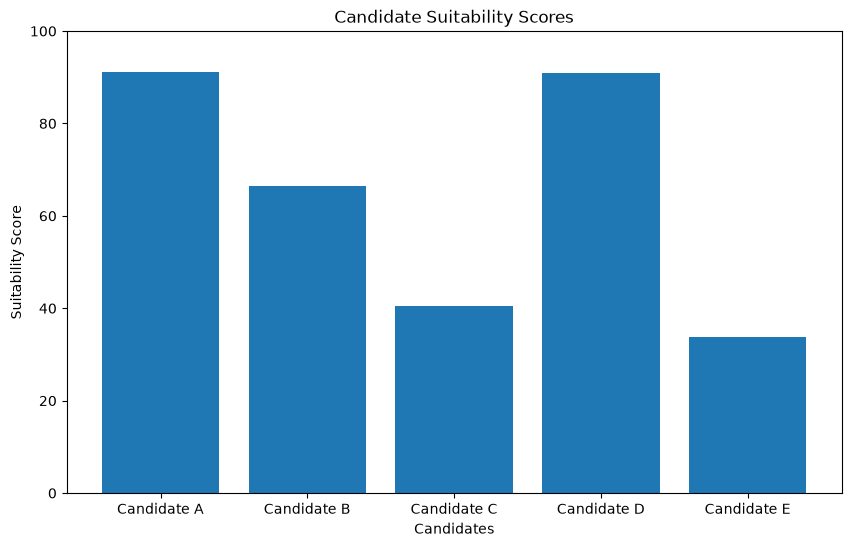

In [57]:
plt.figure(figsize=(10, 6))

plt.bar(
    resume_df["Candidate"],
    resume_df["Suitability_Score"]
)

plt.xlabel("Candidates")
plt.ylabel("Suitability Score")
plt.title("Candidate Suitability Scores")
plt.ylim(0, 100)

plt.show()

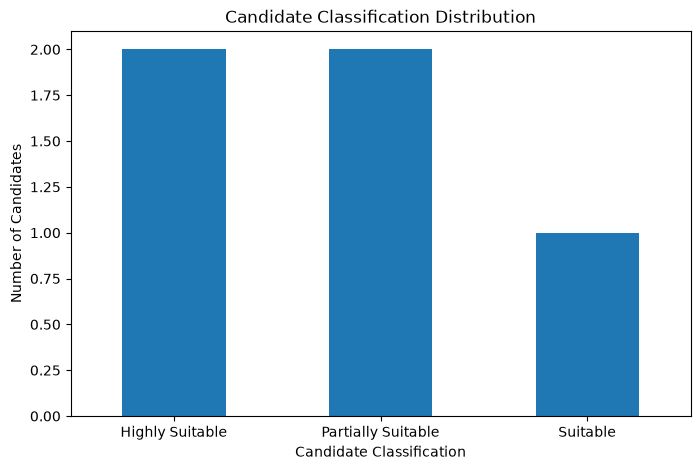

In [58]:
plt.figure(figsize=(8, 5))

resume_df["Classification"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Candidate Classification")
plt.ylabel("Number of Candidates")
plt.title("Candidate Classification Distribution")

plt.xticks(rotation=0)

plt.show()

In [59]:
def generate_report(row):
    report = f"""
========================================
AI RESUME SCREENING REPORT
========================================

Candidate Name:
{row['Candidate']}

Job Applied For:
{job_title}

----------------------------------------
EXTRACTED INFORMATION
----------------------------------------

Qualification:
{row['Qualification']}

Experience:
{row['Experience_Years']} years

Skills Identified:
{', '.join(row['Skills']) if row['Skills'] else 'No required skills found'}

----------------------------------------
ANALYSIS
----------------------------------------

Skill Match:
{row['Skill_Match_Percentage']}%

Experience Score:
{row['Experience_Score']}%

Qualification Score:
{row['Qualification_Score']}%

NLP Similarity:
{row['NLP_Similarity_Score']}%

----------------------------------------
FINAL RESULT
----------------------------------------

Suitability Score:
{row['Suitability_Score']}%

Classification:
{row['Classification']}

========================================
"""

    return report


for index, row in resume_df.iterrows():
    print(generate_report(row))


AI RESUME SCREENING REPORT

Candidate Name:
Candidate A

Job Applied For:
Machine Learning Engineer

----------------------------------------
EXTRACTED INFORMATION
----------------------------------------

Qualification:
Bachelor's Degree

Experience:
3 years

Skills Identified:
python, machine learning, data science, nlp, sql, statistics, data preprocessing, model development

----------------------------------------
ANALYSIS
----------------------------------------

Skill Match:
100.0%

Experience Score:
100.0%

Qualification Score:
100%

NLP Similarity:
55.96%

----------------------------------------
FINAL RESULT
----------------------------------------

Suitability Score:
91.19%

Classification:
Highly Suitable



AI RESUME SCREENING REPORT

Candidate Name:
Candidate B

Job Applied For:
Machine Learning Engineer

----------------------------------------
EXTRACTED INFORMATION
----------------------------------------

Qualification:
Bachelor's Degree

Experience:
2 years

Skills Id

In [60]:
print("=" * 60)
print("AI-BASED RESUME SCREENING & CANDIDATE ANALYSIS SYSTEM")
print("=" * 60)

print("\nJob Position:", job_title)
print("Number of Candidates:", len(resume_df))

print("\nCandidate Results:")
print(
    resume_df[
        ["Candidate", "Suitability_Score", "Classification"]
    ].sort_values(
        by="Suitability_Score",
        ascending=False
    ).to_string(index=False)
)

print("\nProject completed successfully!")

AI-BASED RESUME SCREENING & CANDIDATE ANALYSIS SYSTEM

Job Position: Machine Learning Engineer
Number of Candidates: 5

Candidate Results:
  Candidate  Suitability_Score     Classification
Candidate A              91.19    Highly Suitable
Candidate D              90.94    Highly Suitable
Candidate B              66.46           Suitable
Candidate C              40.50 Partially Suitable
Candidate E              33.76 Partially Suitable

Project completed successfully!
